In [55]:
#TP 4: Les vélos sur le pont de Fremont

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns




In [56]:
# Autre moyen de chercher et télécharger un dossier

from pathlib import Path

URL = "https://data.seattle.gov/api/views/65db-xm6k/rows.csv?accessType=DOWNLOAD"
local_file = "data 4/fremont.csv"

if Path(local_file).exists():
    print(f"le fichier {local_file} est déjà là")
else:
    print(f"allons chercher le fichier {local_file}")

    import requests
    req = requests.get(URL)
    print(req.status_code)

    with open(local_file, 'w') as writer:
        writer.write(req.text)

le fichier data 4/fremont.csv est déjà là


In [57]:
# Chargement

data = pd.read_csv(local_file)
data.shape
data.head()

,Date,Fremont Bridge Total,Fremont Bridge East Sidewalk,Fremont Bridge West Sidewalk
0,08/01/2022 12:00:00 AM,23.0,7.0,16.0
1,08/01/2022 01:00:00 AM,12.0,5.0,7.0
2,08/01/2022 02:00:00 AM,3.0,0.0,3.0
3,08/01/2022 03:00:00 AM,5.0,2.0,3.0
4,08/01/2022 04:00:00 AM,10.0,2.0,8.0


In [ ]:
# Doublons

# Par défaut inplace=false donc on est obligé 
# de spécifier si l'on souhaite qu'il soit True 
data.drop_duplicates(inplace=True)
data.shape


(87600, 4)

In [ ]:
# échauffement : le DatetimeIndex

sample_dates = pd.to_datetime([
    "2024-01-15 08:00:00",
    "2024-01-20 17:30:00",
    "2024-02-03 12:00:00",
])

# 1.
print(type(sample_dates))

# 2.
print(sample_dates.date)
print(sample_dates.time)
print(sample_dates.dayofweek)


<class 'pandas.DatetimeIndex'>
[datetime.date(2024, 1, 15) datetime.date(2024, 1, 20)
 datetime.date(2024, 2, 3)]
[datetime.time(8, 0) datetime.time(17, 30) datetime.time(12, 0)]
Index([0, 5, 5], dtype='int32')


In [ ]:
# 3.

sample_dates[sample_dates >= "2024-01-20"]

DatetimeIndex(['2024-01-20 17:30:00', '2024-02-03 12:00:00'], dtype='datetime64[us]', freq=None)

In [61]:
# question 4

# De ce que je comprends
# sample_dates est un objet spécifique qui est une "liste" de dates
# que panda sait parfaitement lire 
# il reconnait donc l'année et le mois ect.
# le & est important et ne fonctionne pas pareil que le "and"
sample_dates[(sample_dates.year == 2024) & (sample_dates.month == 1)]

DatetimeIndex(['2024-01-15 08:00:00', '2024-01-20 17:30:00'], dtype='datetime64[us]', freq=None)

In [ ]:
# Parser les dates 

# Le rôle de pd.to_datetime est de convertir
# quelque chose qui ressemble à une date mais qui est stocké
# sous la forme d'un texte par exemple
# le "data.index" sert à dire
# que les dates deviennent l'index du DataFrame

data.index = pd.to_datetime(data.Date,format="%m/%d/%Y %I:%M:%S %p")

# On supprime ensuite la colonne Date 
del data["Date"]



In [69]:
# Renommons les colonnes 

data.columns = ['Total', 'West', 'East']


print("Le nombre de lignes avec valeurs manquantes est")

# rôle de isna(): tranformer le tableau en un tableau 
# de booléen selon que la case est remplie ou non 
# True si la case est vide
# rôle de any : est ce qu'il y a au moins un True ?
# (axis=1) pour regarder chaque ligne 
# le tout donne donc:
# On regarde les lignes où il y a au moins une valeur manquante

print(data[data.isna().any(axis=1)].shape[0])
data=data.convert_dtypes(convert_integer=True)




Le nombre de lignes avec valeurs manquantes est
14


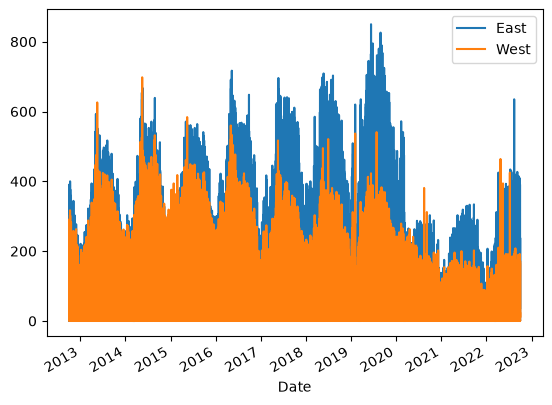

In [70]:
# A quoi ca ressemble

data[["East","West"]].plot()
plt.show()

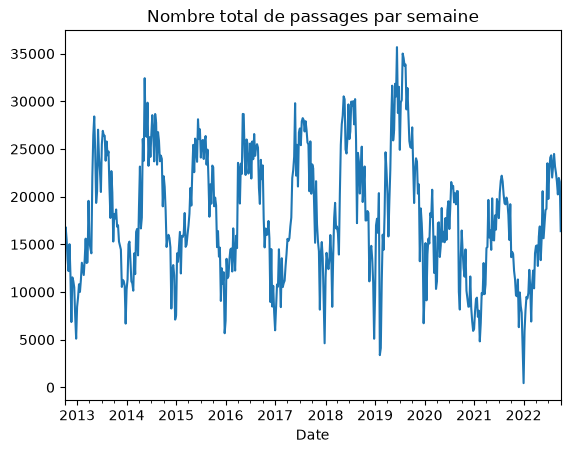

In [ ]:
# resample(): changer la fréquence temporelle


# 1.
# On regroupe par semaine en sommant le nombre de passagers
data_week = data.resample("1W").sum()

# On s'intéresse ici juste au total
data_week["Total"].plot(title="Nombre total de passages par semaine")
plt.show()


In [72]:
# 2.

print("Le nombre de lignes original est :", data.shape[0])
print("Le nombre de semaines est:", data_week.shape[0])
print("Le rapport est donc de :", data.shape[0] / data_week.shape[0])

Le nombre de lignes original est : 87600
Le nombre de semaines est: 522
Le rapport est donc de : 167.816091954023


In [74]:
# Decoupage temporel 

data[data.index.year <= 2017]

# Pour couper au 12 février 2017 à 14h32:30 
# on utilise les comparaisons déjà implémentées sur Panda
# entre dates ;
# data = data[data.index <= "2017-02-12 14:32:30"]



,Total,West,East
Date,,,
2012-10-03 00:00:00,13,4,9
2012-10-03 01:00:00,10,4,6
2012-10-03 02:00:00,2,1,1
2012-10-03 03:00:00,5,2,3
2012-10-03 04:00:00,7,6,1
...,...,...,...
2017-12-31 19:00:00,21,9,12
2017-12-31 20:00:00,14,6,8
2017-12-31 21:00:00,13,3,10


In [ ]:
# Evolution annuelle 